# 02 - Explore interaction profiles and treatment differences

This notebook reads the outputs created in notebook 01. It presents the main profile, topic, and conversational comparisons in a way that is easy to review.


## 1. Load the saved analysis artifacts

Run notebook 01 first. All generated artifacts are centralized under `outputs/research/`.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next(
    (p for p in candidates if (p / "outputs" / "research" / "research_run_summary.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run notebooks/01_text_features_and_data.ipynb first.")
OUT = PROJECT_ROOT / "outputs" / "research"
print(f"Reading results from {OUT}")


Reading results from C:\Users\SrijanWork\Documents\Coding\Data-MIning-Project\outputs\research


## 2. How many profiles should we use?

Several cluster counts and algorithms are compared. The cluster labels are descriptive groups made from selected interaction features; treatment and exam results are not used to form them.

In [2]:
k_metrics = pd.read_csv(OUT / "tables" / "cluster_k_selection_metrics.csv")
algorithm_comparison = pd.read_csv(OUT / "tables" / "cluster_algorithm_comparison.csv")
cluster_profiles = pd.read_csv(OUT / "tables" / "cluster_feature_profiles.csv")
display(k_metrics)
display(algorithm_comparison)
display(cluster_profiles)


,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,7312.346066,0.361096,1.619038,105.400568
1,3,6541.490281,0.279505,2.010275,89.140429
2,4,5931.881479,0.263386,1.683886,83.014522
3,5,5515.762439,0.256181,1.436199,76.503108
4,6,5068.609052,0.280948,1.255782,75.505692
5,7,4772.473153,0.161386,1.424776,71.979878
6,8,4474.272081,0.174120,1.425518,70.536014


,algorithm,k,silhouette,davies_bouldin,calinski_harabasz
0,KMeans,4,0.263386,1.683886,83.014522
1,Agglomerative_Ward,4,0.231666,1.629404,68.581883


,kmeans_cluster,student_message_count,average_word_count,average_question_count,explanation_request_rate,complete_solution_request_rate,verification_request_rate,conceptual_question_rate,code_prompt_rate,followup_prompt_rate,text_lexical_diversity_mean,text_mean_words_per_sentence_mean,text_math_terminology_present_mean,text_independent_attempt_mean,text_reasoning_explanation_mean,text_specific_difficulty_mean,text_why_correct_request_mean,text_direct_answer_request_mean,text_challenge_or_verification_mean
0,0,46.448276,9.387932,0.182390,0.016271,0.162422,0.224753,0.146850,0.028683,0.045468,0.953556,7.061447,0.234660,0.014453,0.005889,0.000884,0.0,0.091217,0.224753
1,1,66.710526,4.956778,0.073048,0.014278,0.047059,0.005658,0.067107,0.006258,0.009315,0.974482,4.831030,0.082833,0.045849,0.002218,0.000233,0.0,0.027382,0.005168
2,2,29.646341,5.139787,0.038434,0.015095,0.276157,0.012250,0.216481,0.003837,0.011614,0.982368,4.945592,0.274955,0.009473,0.000249,0.000000,0.0,0.183487,0.012250
3,3,31.861538,19.801225,0.213436,0.016042,0.058429,0.007639,0.185393,0.109973,0.015499,0.835271,13.423074,0.336305,0.029460,0.013113,0.000000,0.0,0.031923,0.006374


student_profiles_pca.png


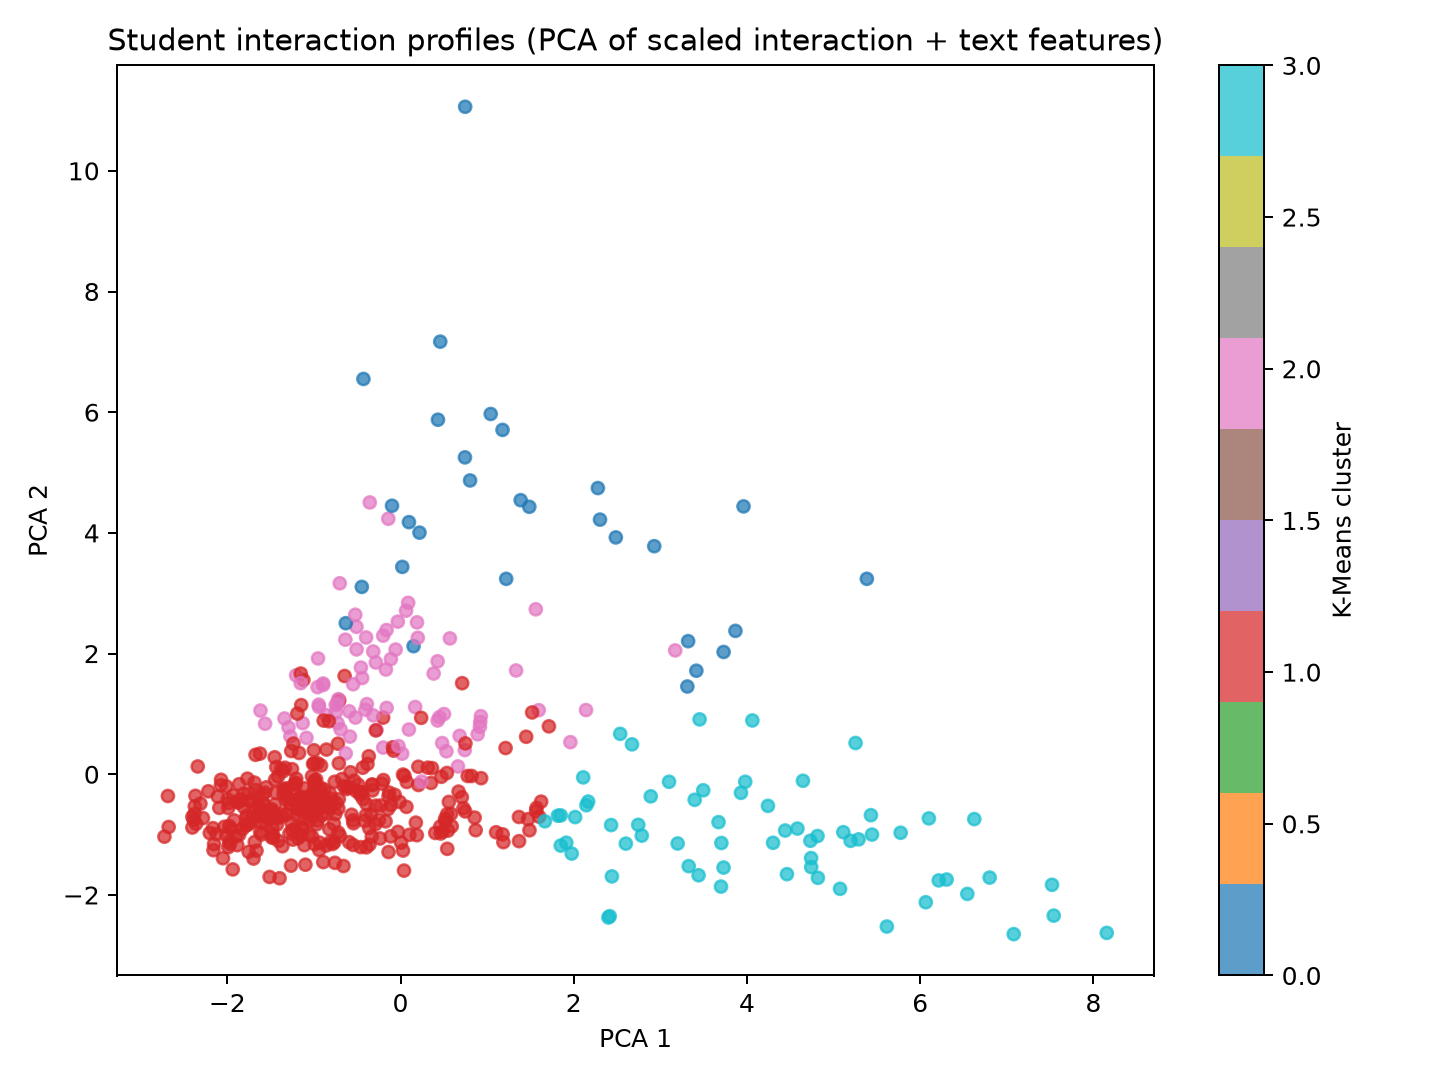

kmeans_elbow.png


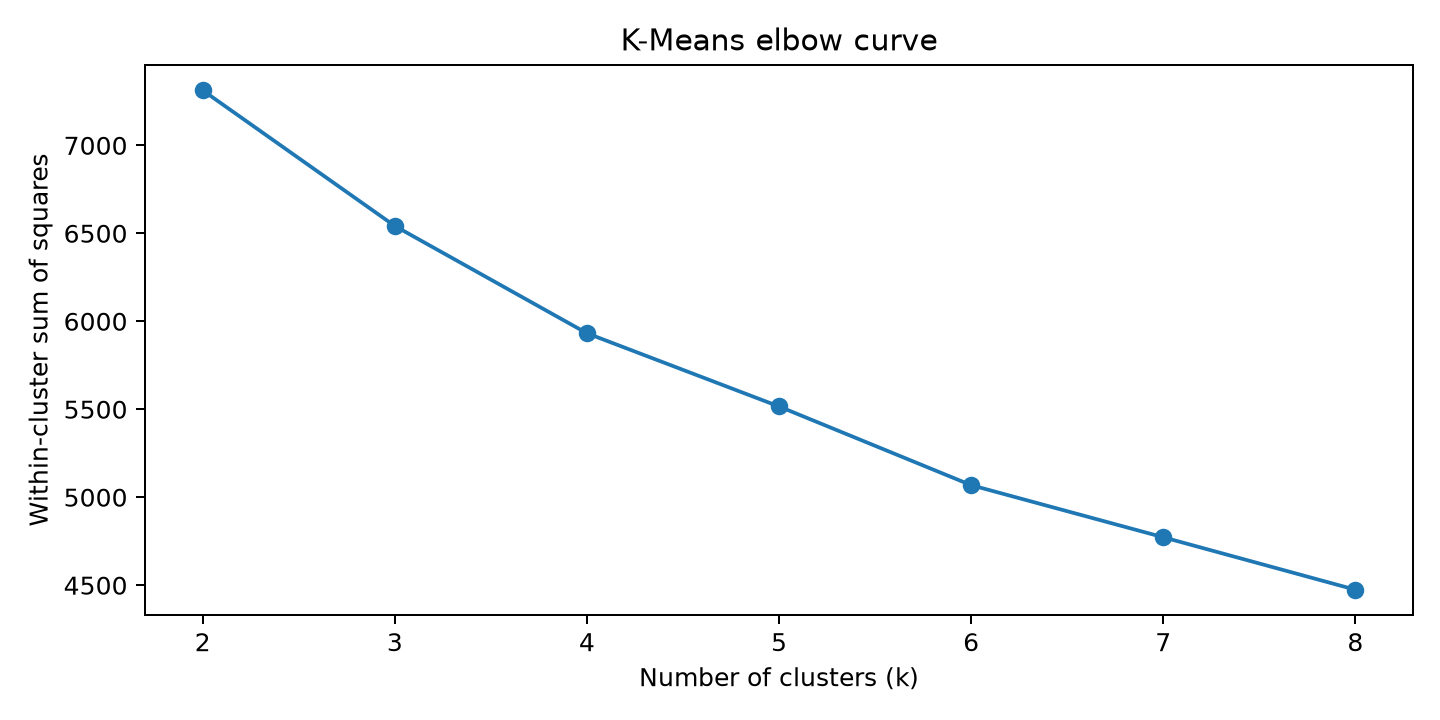

In [3]:
for name in ["student_profiles_pca.png", "kmeans_elbow.png"]:
    path = OUT / "figures" / name
    if path.is_file():
        print(name)
        display(Image(filename=str(path)))


## 3. Compare profiles across the two AI arms

These summaries compare the profiles after clustering. They help describe who appears in each cluster; they do not make the clustering a treatment-effect estimate.

In [4]:
cluster_by_treatment = pd.read_csv(OUT / "tables" / "cluster_by_treatment.csv")
text_associations = pd.read_csv(OUT / "tables" / "class_clustered_treatment_text_associations.csv")
display(cluster_by_treatment)
display(text_associations.sort_values("fdr_q_value").head(15))


,kmeans_cluster,aug,vanilla
0,0,0,29
1,1,254,88
2,2,11,71
3,3,12,53


,feature,treatment_contrast,coefficient_sd,cluster_robust_se,ci95_low,ci95_high,p_value,students,classes,grade_adjusted,fdr_q_value
0,mean_response_word_count,GPT Tutor (aug) - GPT Base (vanilla),-1.703001,0.069623,-1.846112,-1.559890,1.791626e-19,518,27,True,6.987340e-18
1,response_hint_or_scaffold_rate,GPT Tutor (aug) - GPT Base (vanilla),1.367664,0.097716,1.166806,1.568523,1.288264e-13,518,27,True,2.512115e-12
2,response_explanation_rate,GPT Tutor (aug) - GPT Base (vanilla),-1.198279,0.103641,-1.411317,-0.985241,9.516390e-12,518,27,True,1.237131e-10
3,conceptual_question_rate,GPT Tutor (aug) - GPT Base (vanilla),-0.728629,0.067993,-0.868390,-0.588868,4.925191e-11,518,27,True,4.802061e-10
4,assistant_turn_count,GPT Tutor (aug) - GPT Base (vanilla),1.034995,0.115994,0.796566,1.273425,2.151884e-09,518,27,True,1.398724e-08
5,student_message_count,GPT Tutor (aug) - GPT Base (vanilla),1.039895,0.116067,0.801316,1.278473,1.983914e-09,518,27,True,1.398724e-08
6,response_guided_question_rate,GPT Tutor (aug) - GPT Base (vanilla),0.790284,0.097925,0.588997,0.991571,1.500630e-08,518,27,True,8.360652e-08
7,response_direct_answer_rate,GPT Tutor (aug) - GPT Base (vanilla),-0.695367,0.094774,-0.890178,-0.500555,8.608751e-08,518,27,True,4.196766e-07
8,hint_request_present,GPT Tutor (aug) - GPT Base (vanilla),0.459063,0.085853,0.282590,0.635536,1.347712e-05,518,27,True,5.256077e-05
9,text_direct_answer_request_mean,GPT Tutor (aug) - GPT Base (vanilla),-0.661384,0.123512,-0.915266,-0.407502,1.320580e-05,518,27,True,5.256077e-05


treatment_text_feature_effects.png


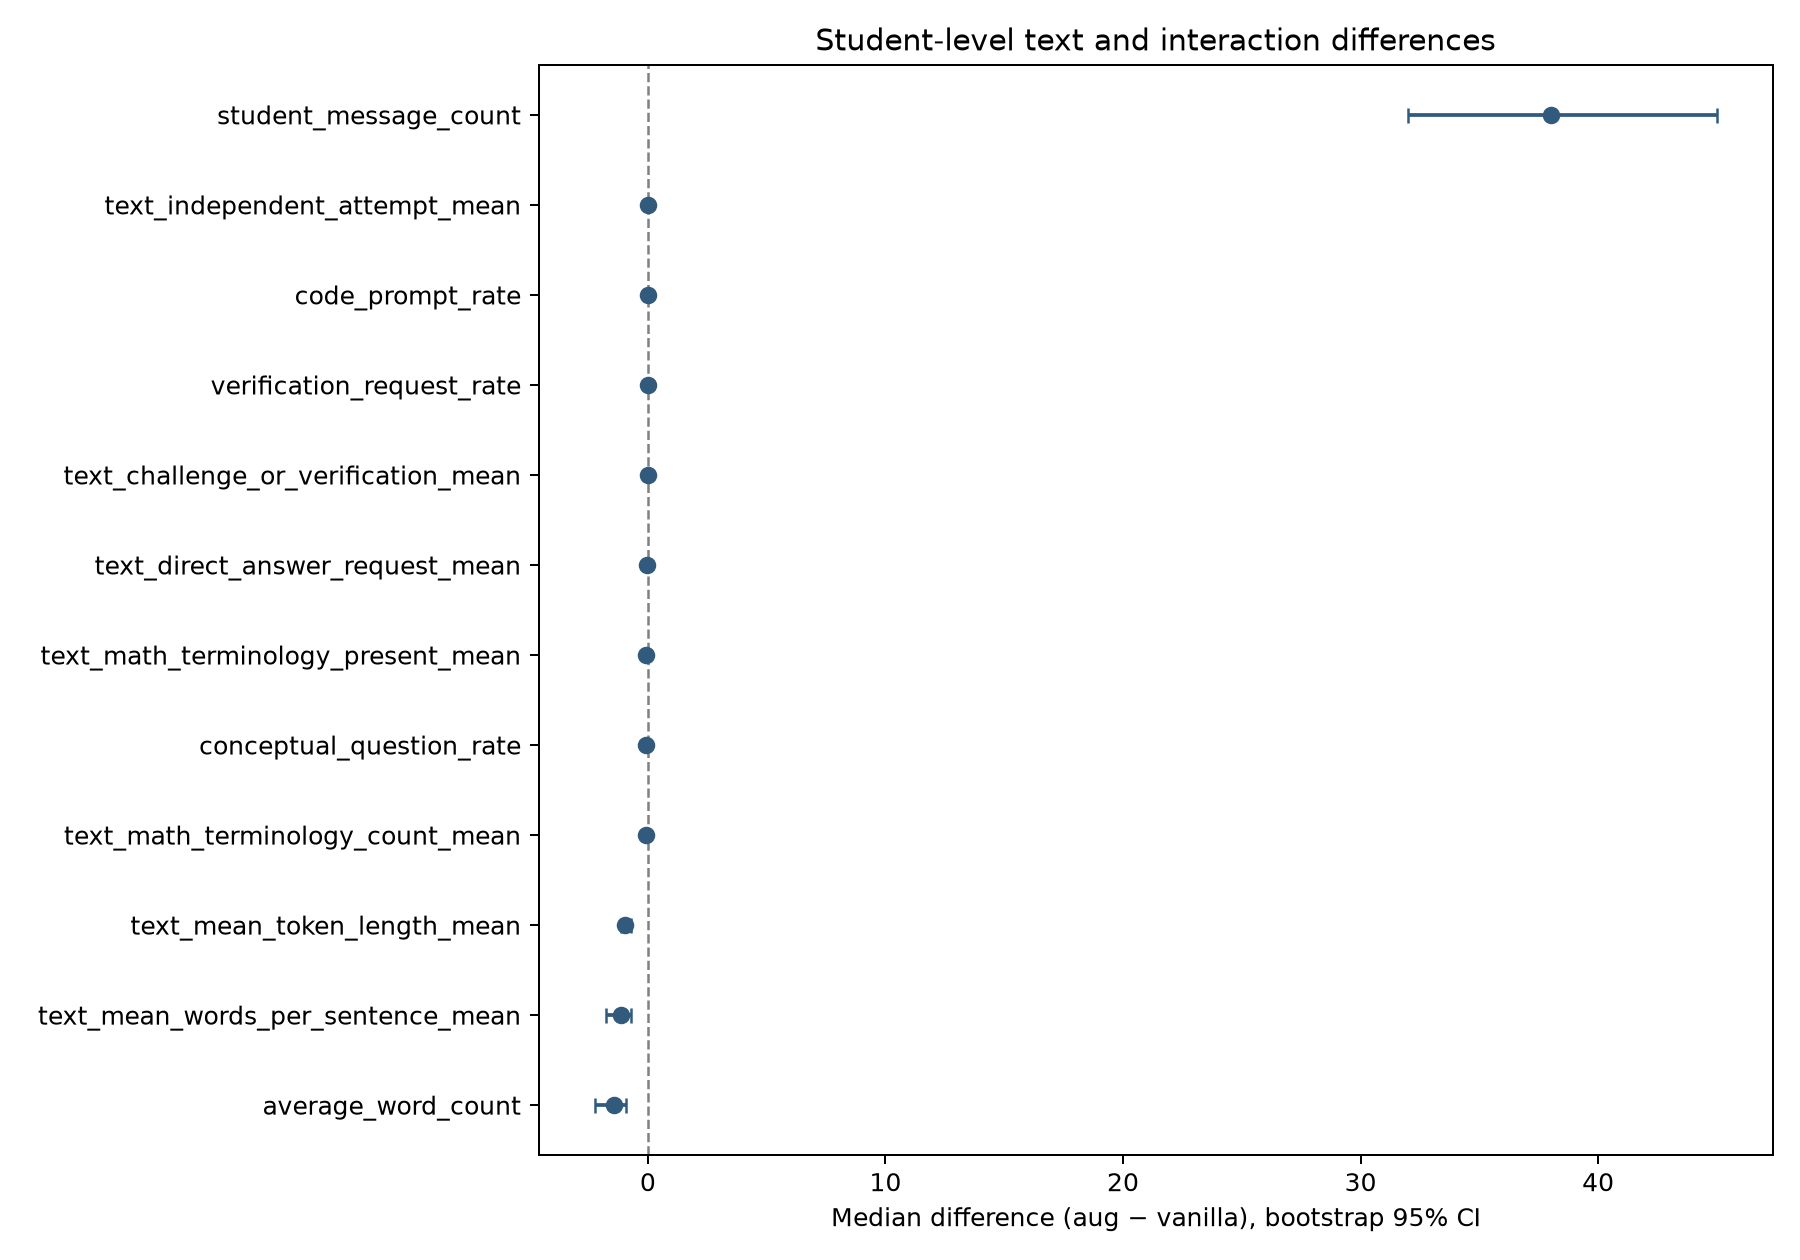

lexical_topics_by_treatment.png


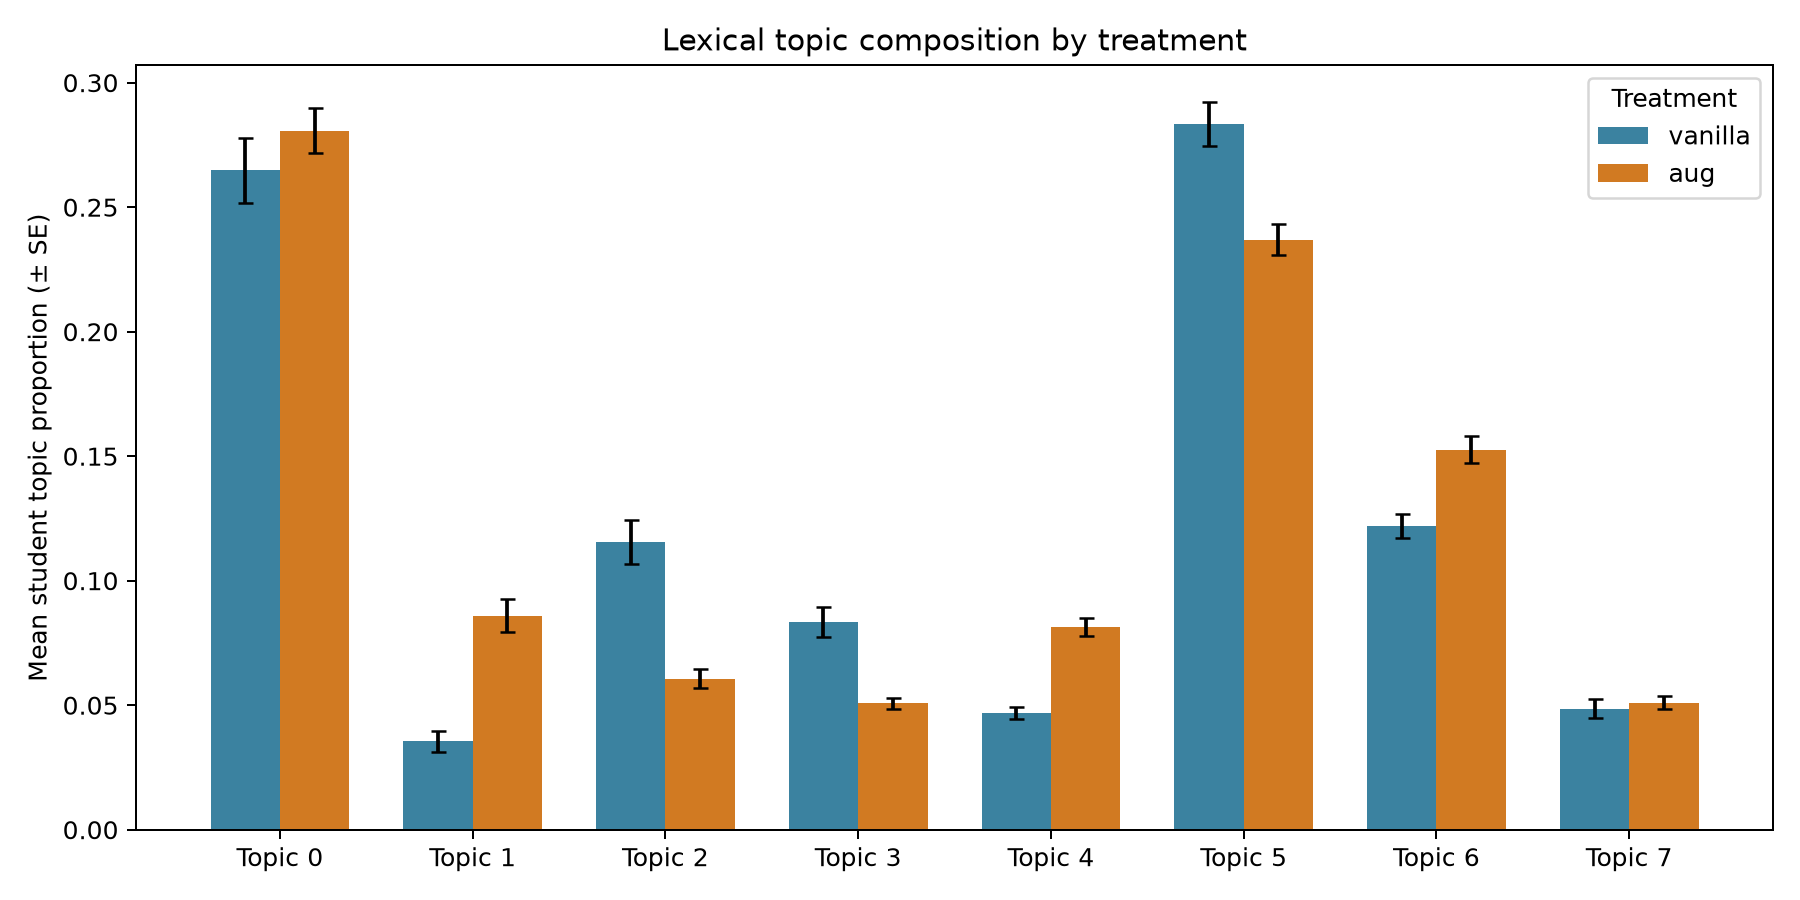

In [5]:
for name in ["treatment_text_feature_effects.png", "lexical_topics_by_treatment.png"]:
    path = OUT / "figures" / name
    if path.is_file():
        print(name)
        display(Image(filename=str(path)))


## 4. Read recurring prompt themes and actual assistant turns

Themes are exploratory word-pattern groups. Assistant-response features come from the separate full conversation export, not from the student-only message CSV. The response categories are simple text cues and can overlap.

In [6]:
topics = pd.read_csv(OUT / "tables" / "lexical_nmf_topics.csv")
topic_comparison = pd.read_csv(OUT / "tables" / "lexical_topic_treatment_comparison.csv")
assistant_tests = pd.read_csv(OUT / "tables" / "assistant_response_treatment_tests.csv")
followup_summary = pd.read_csv(OUT / "tables" / "student_followup_after_response_summary.csv")
display(topics)
display(topic_comparison.sort_values("fdr_q_value").head(15))
display(assistant_tests)
display(followup_summary.head(20))


,topic,top_terms,message_count
0,0,"answer, whats answer, whats, answer question, ...",5874
1,1,"help, help solve, help figure, understand, fig...",1264
2,2,"solve, solve question, help solve, solve probl...",1263
3,3,"sure, sure answer, 100, correct, 14, true, rea...",1043
4,4,"yes, continue, yes answer, yes continue, thank...",1154
5,5,"question, solve question, answer question, und...",7658
6,6,"dont, know, dont know, understand, dont unders...",2799
7,7,"problem, solve problem, figure, help figure, f...",955


,topic_share,aug_mean,vanilla_mean,median_difference_aug_minus_vanilla,median_difference_ci95_low,median_difference_ci95_high,rank_biserial_r,p_value,fdr_q_value
1,topic_1_share,0.085931,0.035533,0.028792,0.021466,0.037644,0.459619,1.867217e-19,1.493773e-18
4,topic_4_share,0.081513,0.046885,0.027830,0.019950,0.036451,0.413675,4.700582e-16,1.880233e-15
5,topic_5_share,0.236990,0.283536,-0.061756,-0.086577,-0.037513,-0.230230,6.228331e-06,1.660888e-05
6,topic_6_share,0.152527,0.121828,0.016984,0.003609,0.030846,0.202297,7.180130e-05,1.436026e-04
2,topic_2_share,0.060552,0.115620,-0.016195,-0.035964,-0.005172,-0.198148,1.007370e-04,1.611793e-04
0,topic_0_share,0.280732,0.264744,0.050400,0.018055,0.096034,0.120512,1.802872e-02,2.403829e-02
3,topic_3_share,0.050789,0.083296,-0.005175,-0.015721,0.001987,-0.116573,2.215395e-02,2.531880e-02
7,topic_7_share,0.050967,0.048559,0.004650,-0.003894,0.012075,0.109928,3.098270e-02,3.098270e-02


,feature,aug_median,vanilla_median,median_difference_aug_minus_vanilla,median_difference_ci95_low,median_difference_ci95_high,rank_biserial_r,p_value,fdr_q_value
0,mean_response_word_count,86.700000,176.000000,-89.300000,-93.992089,-81.970110,-0.976452,5.342095e-82,2.671048e-81
1,response_direct_answer_rate,0.121212,0.207547,-0.086335,-0.101010,-0.068548,-0.440748,4.747734e-18,4.747734e-18
2,response_hint_or_scaffold_rate,0.340426,0.134328,0.206097,0.186992,0.219300,0.791782,1.498109e-54,3.745271e-54
3,response_explanation_rate,0.195652,0.421053,-0.225400,-0.248869,-0.188312,-0.726396,3.405093e-46,5.675156e-46
4,response_guided_question_rate,0.000000,0.000000,0.000000,0.000000,0.006536,0.433003,9.035918e-30,1.129490e-29


,response_type,student_count,mean_student_followup_words,median_student_followup_words,mean_question_followup_rate,mean_attempt_cue_rate,mean_reasoning_cue_rate
0,response_direct_answer,451,5.315993,4.000000,0.058972,0.039326,0.002645
1,response_explanation,492,5.717834,4.333333,0.056999,0.042881,0.004132
2,response_guided_question,118,4.734181,3.208333,0.039831,0.039548,0.008475
3,response_hint_or_scaffold,465,5.650647,4.000000,0.054361,0.047096,0.004752


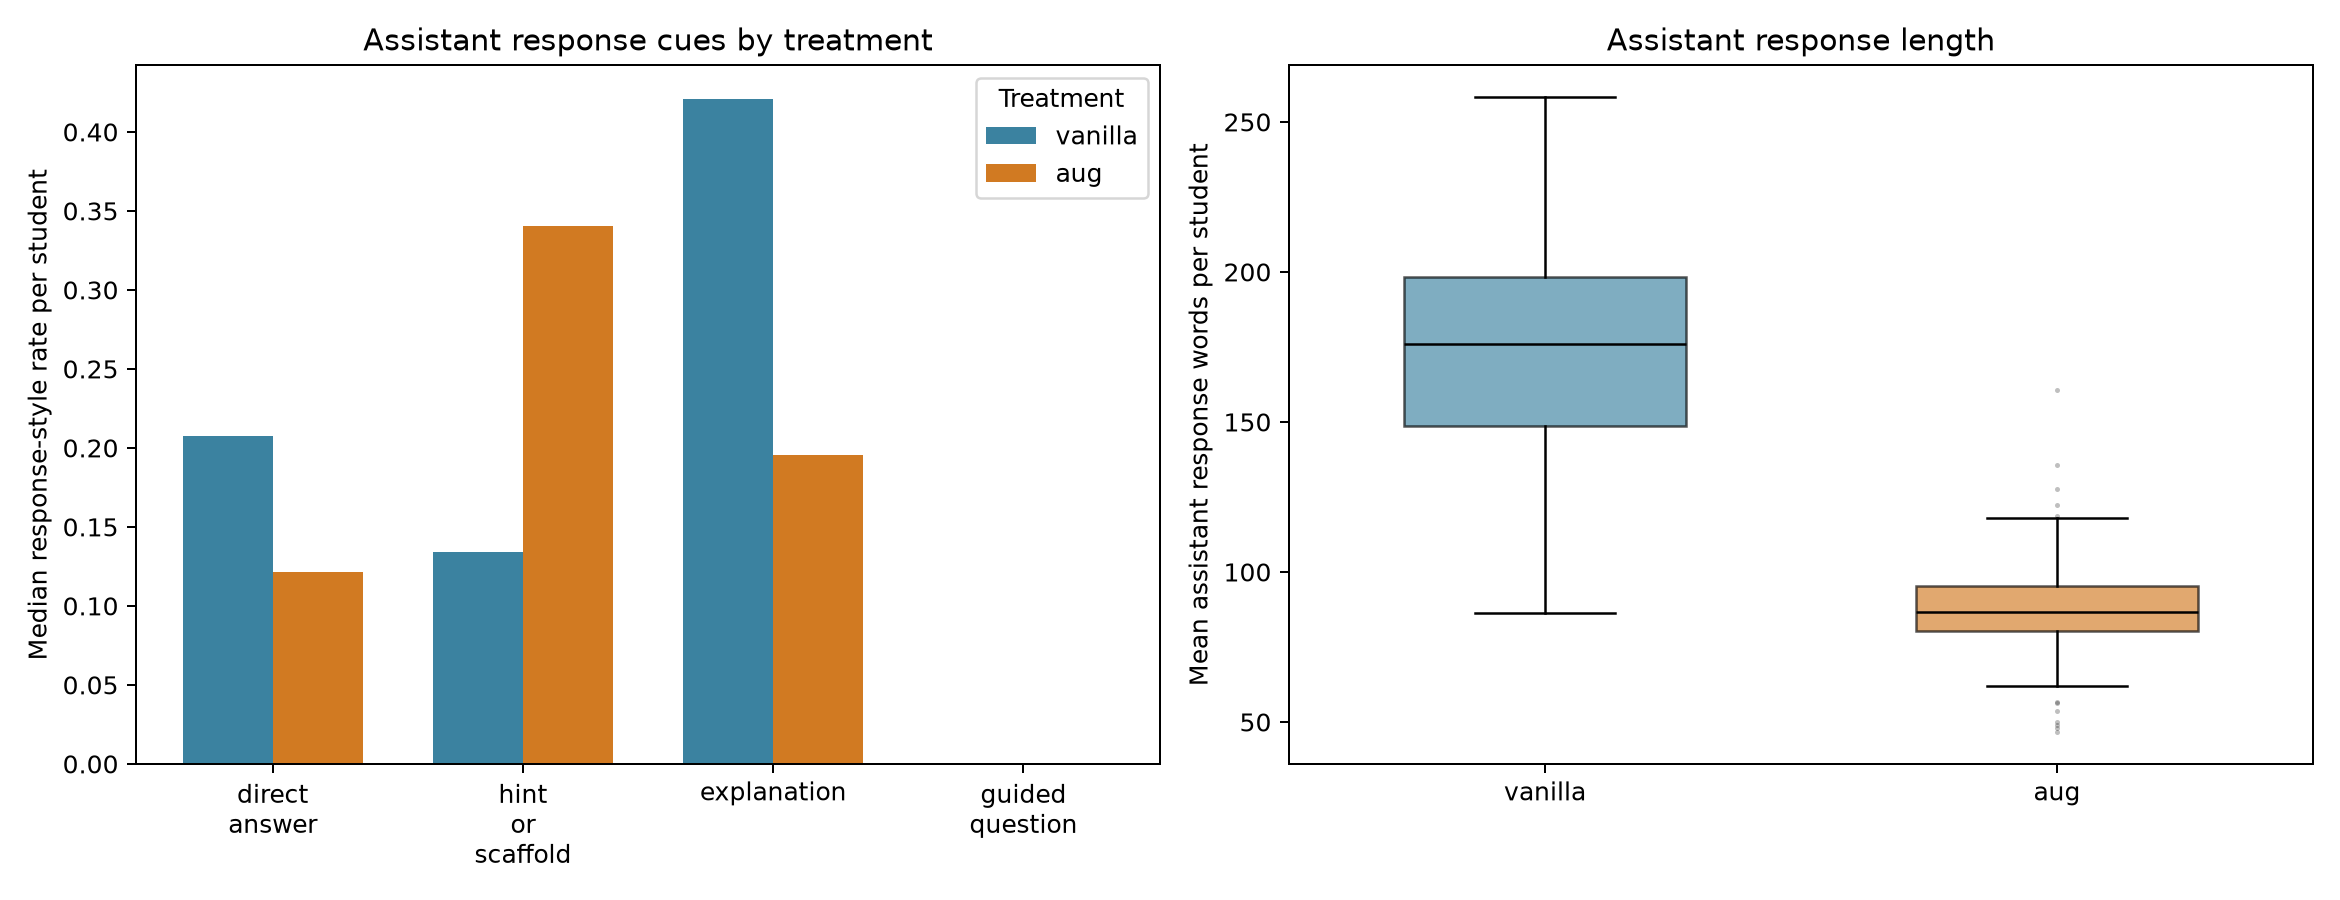

In [7]:
path = OUT / "figures" / "assistant_response_treatment_comparison.png"
if path.is_file():
    display(Image(filename=str(path)))


## What this step tells us

It describes how the saved text and conversation features vary across interaction profiles and AI arms. It does **not** establish that GPT Base or GPT Tutor caused a particular prompt style, or that a prompt style measures understanding. For score prediction and score comparisons, continue with [03 - Learning outcomes](03_learning_outcomes.ipynb).


## Questions you may be asked

- **What is a cluster?** It is a computer-made group of students with similar measured interaction features. It is a summary tool, not a discovered student type.
- **Did treatment or exam scores define the clusters?** No. Clusters are made from interaction features first; treatment and grade are compared afterward.
- **Are the prompt themes definitive?** No. They are exploratory word-pattern themes, and the assistant-style labels are simple text cues.
